# Friuli: snow depth of the porting against the observations

Phase 2.2 of the prototype plan (VAL-3, ORG-1). Four stations of the Friuli Venezia Giulia network,
1 November 2025 – 1 May 2026, hourly. The porting runs in the **recommended configuration**, heat only
(GEOtop's `WaterBalance = 0`), on flat ground, through the OMS3 component `SnowSoilSolver1DMain`
(`snowsoil_friuli.sim`, `run_all.sh`). For information, the same snow depth from:

- **GEOtop 3.0** (commit 1f1fc5af), the case converted from the MobyGIS run (`casi/Friuli/converti.py`,
  `run.sh`, outside this repository): *flat* (as the porting: no slope, no horizon) and *topography*
  (slope, aspect and sky view of the 250 m maps, horizon of the point, as the MobyGIS run);
- the **MobyGIS-GEOtop** run the case comes from (`pysnow/tests/gt_sim1D/output_tabs`, GEOtop 2.0
  "TN-EXACT" with MeteoIO);
- two **sensitivity** runs of the porting, not references: with the stability correction of the GEOtop
  runs (`MoninObukhov = 2`: unstable side only, `STABILITY="Unstable only" run_all.sh`), and without the
  shortwave penetration of the recommended configuration (SNOW-7, `SW=None run_all.sh`).

Nothing is tuned: the porting uses the library's recommended parameters; the case's own snow
parameters (albedo ageing, extinction, layering) enter only the GEOtop runs.

Paths: set `FRIULI_GT3` (the `gt3/` folder of the case) and `FRIULI_MOBYGIS` (the MobyGIS `output_tabs/`)
if they are not in their default places; missing runs are skipped.

In [1]:
import os, re, glob
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import compare

hs, swe = compare.load()
STATIONS = compare.STATIONS
STYLE = {'observed': dict(color='black', lw=1.6),
         'porting': dict(color='#1f77b4', lw=1.4),
         'porting, unstable only': dict(color='#1f77b4', lw=1.0, ls='--'),
         'GEOtop 3.0 flat': dict(color='#d62728', lw=1.2),
         'GEOtop 3.0 topography': dict(color='#ff7f0e', lw=1.0, ls='--'),
         'MobyGIS': dict(color='#2ca02c', lw=1.0, ls=':')}
print({s: list(hs[s].columns) for s in hs})

{1: ['observed', 'porting', 'porting, no shortwave penetration', 'GEOtop 3.0 flat', 'GEOtop 3.0 topography', 'MobyGIS'], 2: ['observed', 'porting', 'porting, no shortwave penetration', 'GEOtop 3.0 flat', 'GEOtop 3.0 topography', 'MobyGIS'], 3: ['observed', 'porting', 'porting, no shortwave penetration', 'GEOtop 3.0 flat', 'GEOtop 3.0 topography', 'MobyGIS'], 4: ['observed', 'porting', 'porting, no shortwave penetration', 'GEOtop 3.0 flat', 'GEOtop 3.0 topography', 'MobyGIS']}


## Snow depth

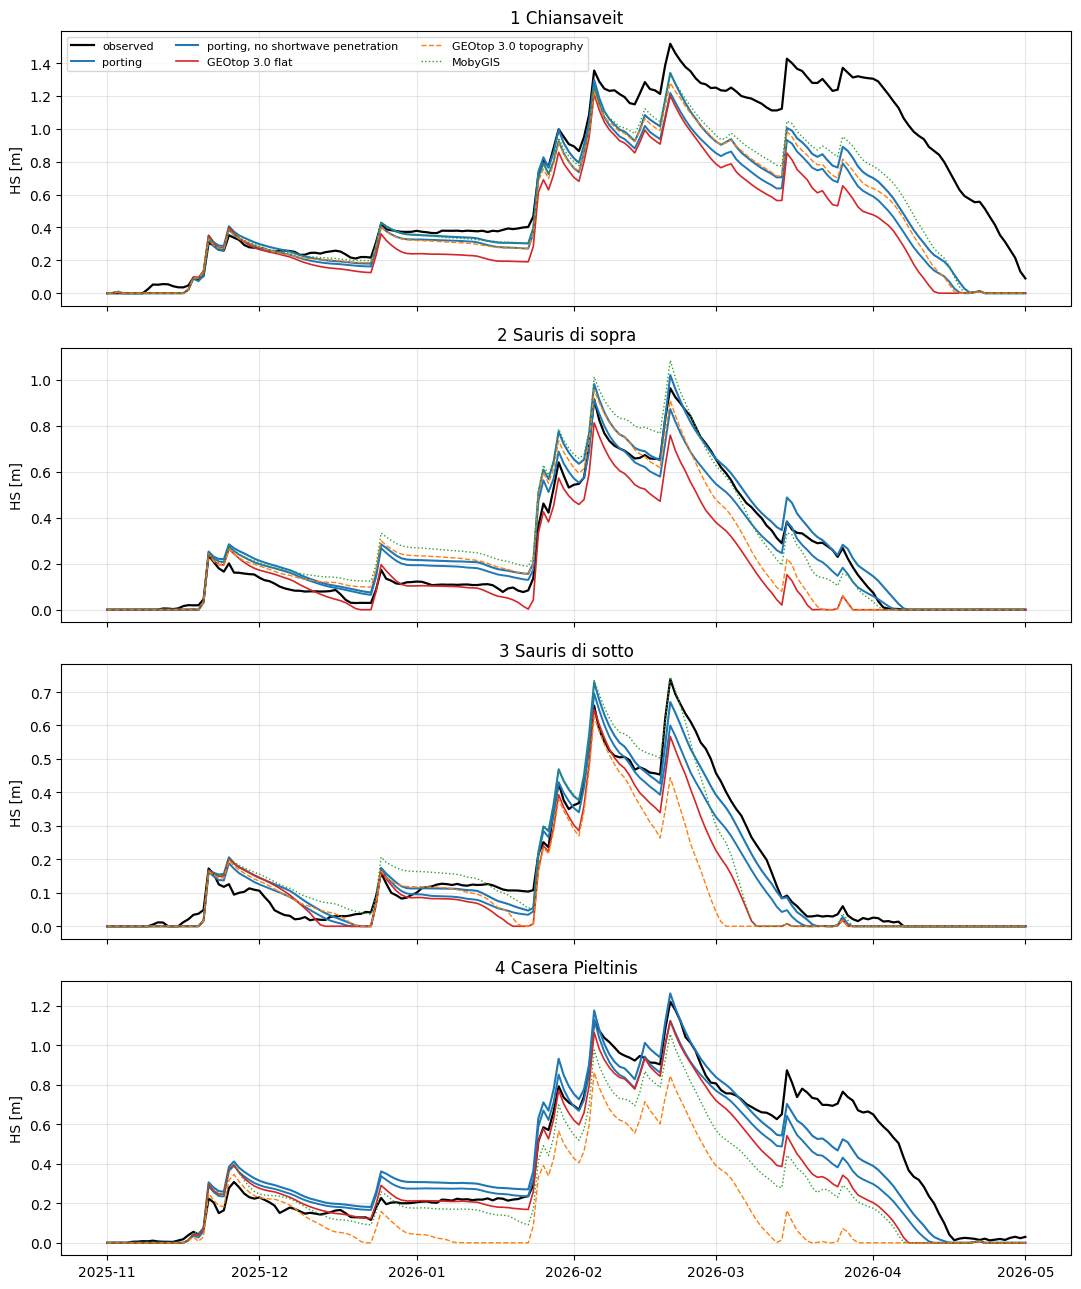

In [2]:
fig, axes = plt.subplots(4, 1, figsize=(11, 13), sharex=True)
for ax, (s, name) in zip(axes, STATIONS.items()):
    daily = hs[s].resample('D').mean()
    for col in daily.columns:
        ax.plot(daily.index, daily[col], label=col, **STYLE.get(col, {}))
    ax.set_title(f'{s} {name}')
    ax.set_ylabel('HS [m]')
    ax.grid(alpha=0.3)
axes[0].legend(ncol=3, fontsize=8)
fig.tight_layout()

## Scores

Daily means; bias and RMSE of the run minus the observation over the days with an observation.
Onset: first day with HS ≥ 5 cm; melt-out: the day after the last one.

In [3]:
tables = {}
for s, name in STATIONS.items():
    tables[s] = compare.metrics(hs[s])
    print(f'\n{s} {name}')
    print(tables[s].round(3).to_string())
    print('max SWE [mm]: ' + ', '.join(f'{k} {v:.0f}' for k, v in swe[s].max().items()))


1 Chiansaveit
                                   bias [m]  RMSE [m]  max HS [m] date of max       onset    melt-out  days with snow
run                                                                                                                  
observed                                NaN       NaN       1.518  2026-02-20  2025-11-10  2026-05-02             169
porting                              -0.242     0.344       1.261  2026-02-05  2025-11-18  2026-04-17             150
porting, no shortwave penetration    -0.197     0.293       1.340  2026-02-20  2025-11-18  2026-04-19             152
GEOtop 3.0 flat                      -0.293     0.398       1.211  2026-02-05  2025-11-18  2026-04-12             145
GEOtop 3.0 topography                -0.222     0.317       1.280  2026-02-20  2025-11-18  2026-04-17             150
MobyGIS                              -0.182     0.266       1.335  2026-02-20  2025-11-18  2026-04-18             151
max SWE [mm]: porting 346, porting, no sh

In [4]:
summary = pd.concat({STATIONS[s]: t[['bias [m]', 'RMSE [m]']] for s, t in tables.items()}).unstack(0)
summary = summary.drop(index='observed', errors='ignore')
summary.round(3)

bias [m]                                  \
                                  Chiansaveit Sauris di sopra Sauris di sotto   
run                                                                             
porting                                -0.242           0.005          -0.022   
porting, no shortwave penetration      -0.197           0.047          -0.003   
GEOtop 3.0 flat                        -0.293          -0.070          -0.042   
GEOtop 3.0 topography                  -0.222          -0.006          -0.054   
MobyGIS                                -0.182           0.043          -0.001   

                                                      RMSE [m]  \
                                  Casera Pieltinis Chiansaveit   
run                                                              
porting                                     -0.045       0.344   
porting, no shortwave penetration           -0.005       0.293   
GEOtop 3.0 flat                             -0.087       0.398   
GEOtop 3.0 topography                       -0.236       0.317   
MobyGIS                                     -0.130       0.266   

                                                                   \
                                  Sauris di sopra Sauris di sotto   
run                                                                 
porting                                     0.059           0.053   
porting, no shortwave penetration           0.064           0.039   
GEOtop 3.0 flat                             0.126           0.086   
GEOtop 3.0 topography                       0.107           0.124   
MobyGIS                                     0.092           0.069   

                                                    
                                  Casera Pieltinis  
run                                                 
porting                                      0.132  
porting, no shortwave penetration            0.107  
GEOtop 3.0 flat                              0.170  
GEOtop 3.0 topography                        0.329  
MobyGIS                                      0.207

## Snow water equivalent of the models

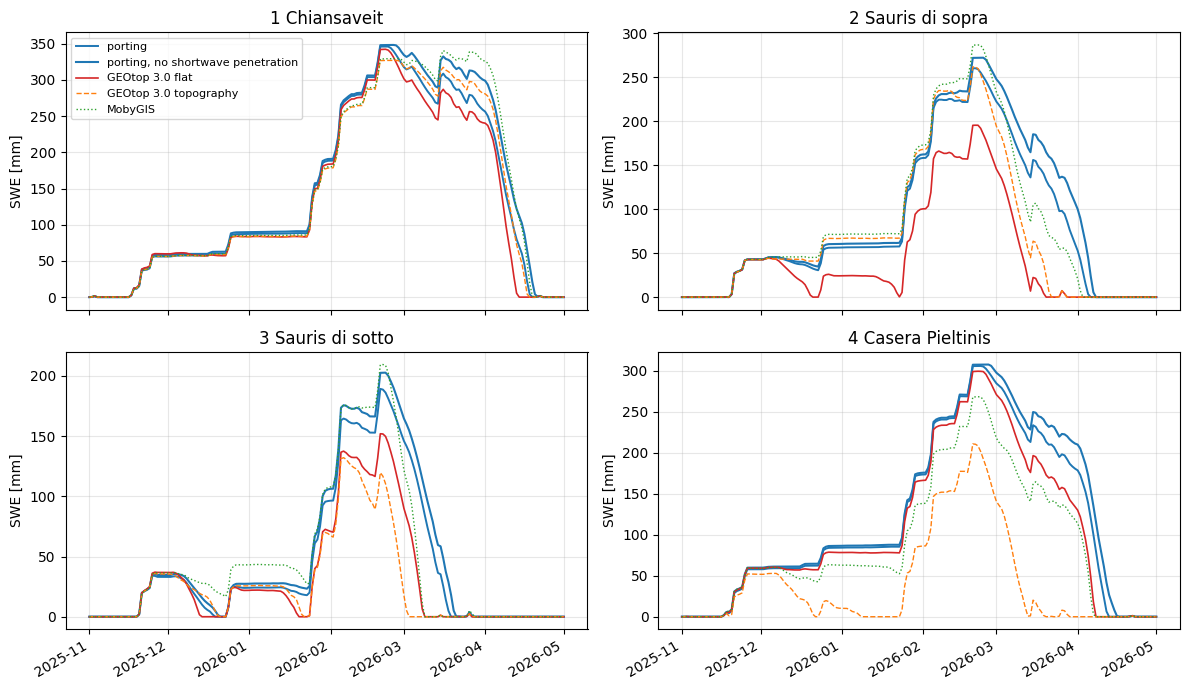

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
for ax, (s, name) in zip(axes.flat, STATIONS.items()):
    daily = swe[s].resample('D').mean()
    for col in daily.columns:
        ax.plot(daily.index, daily[col], label=col, **STYLE.get(col, {}))
    ax.set_title(f'{s} {name}')
    ax.set_ylabel('SWE [mm]')
    ax.grid(alpha=0.3)
axes[0, 0].legend(fontsize=8)
fig.autofmt_xdate()
fig.tight_layout()

## Step control on real forcing (SOL-5) and run time

The component prints every rejected step and a summary at the end of the run (`output/station_<n>.log`).

In [6]:
for log in sorted(glob.glob(os.path.join(compare.HERE, 'output', '*.log'))):
    lines = [l.strip() for l in open(log) if l.startswith('snowsoil:')]
    print(os.path.basename(log), '|', ' / '.join(lines) if lines else 'no summary')

station_1.log | snowsoil: 4344 steps, 4344 accepted solver steps, 0 rejected, 0 degraded / snowsoil: column balance (VAL-7), worst step 1.86e-13 kg m-2 and 0.313 J m-2, run -4.40e-13 kg m-2 and 4.49 J m-2 (of which explained -3.41e-14 kg m-2 and 4.49 J m-2)
station_1_sw_none.log | snowsoil: 4344 steps, 4344 accepted solver steps, 0 rejected, 0 degraded / snowsoil: column balance (VAL-7), worst step 1.81e-13 kg m-2 and 0.244 J m-2, run 8.46e-14 kg m-2 and 6.20 J m-2 (of which explained 3.48e-13 kg m-2 and 6.20 J m-2)
station_2.log | snowsoil: 4344 steps, 4344 accepted solver steps, 0 rejected, 0 degraded / snowsoil: column balance (VAL-7), worst step 9.66e-14 kg m-2 and 0.0991 J m-2, run 1.25e-13 kg m-2 and 3.32 J m-2 (of which explained -1.73e-13 kg m-2 and 3.32 J m-2)
station_2_sw_none.log | snowsoil: 4344 steps, 4344 accepted solver steps, 0 rejected, 0 degraded / snowsoil: column balance (VAL-7), worst step 1.29e-13 kg m-2 and 0.206 J m-2, run 3.69e-13 kg m-2 and 6.41 J m-2 (of whic

## Why the runs differ

- **Same forcing, same precipitation split.** Porting and GEOtop 3.0 flat receive the same snowfall
  and rainfall at every station (ramp 0.5–2 °C on the air temperature, `SnowCorrFactor = 1`); the
  differences in SWE come from the energy balance and the pack, not from the input.
- **Stability.** The GEOtop runs use `MoninObukhov = 2` (no stable correction), the recommended
  configuration both sides (GEOtop's default). Without the stable correction the turbulent exchange stays
  strong under the stable stratification of a cold pack, the sensible heat into the snow grows (at
  Sauris di sopra about −12 W m⁻² in GEOtop 3.0 against −3 W m⁻² in the porting over the snow-covered hours)
  and thin early-winter packs melt in December–January. The porting with the same option (dashed blue)
  moves about half of the way towards GEOtop 3.0.
- **Shortwave penetration (SNOW-7).** The recommended configuration absorbs the net shortwave inside the
  pack with the attenuation compounded cell by cell, none at the skin. The interior warms and settles
  faster: at the same SWE peak (Chiansaveit 346 against 348 mm, Casera Pieltinis 306 against 308 mm) the
  maximum depth is 8–13 cm lower, and the pack melts out 2–4 days earlier. Against the observation the
  RMSE grows by 0.01–0.05 m at three stations and falls by 0.005 m at Sauris di sopra; the porting stays
  closer to the observation than GEOtop 3.0 flat at all four.
- **Snow parameters.** The GEOtop runs use the case's albedo and pack parameters (`FreshSnowReflNIR = 0.85`,
  ageing 0.35/0.75, `AlbExtParSnow = 50`, three middle layers, `SWEtop = 75`, `SWEbottom = 30`);
  the porting the library's recommended set (GEOtop's default albedo, recommended compaction and
  restratification). Not changed here: the plan runs Friuli in the recommended configuration.
- **Bare ground and soil.** Before the first snow and in the snow-free gaps, GEOtop solves a surface
  energy balance on the soil; the porting uses a bulk transfer h (T<sub>a</sub> − T<sub>top</sub>), h = 10
  W m⁻² K⁻¹ (COL-6). The soil is GEOtop's three layers (0.28, 0.50, 2.00 m) in both, but with WHETGEO's
  thermal conductivity (Cosenza) against GEOtop's.
- **Time interpolation of the forcing.** GEOtop 3.0 averages the linear interpolation of the hourly
  records over the step; the porting takes the record of the step as it is. The MobyGIS run (GEOtop 2 +
  MeteoIO) uses the records one hour earlier than GEOtop 3.0 on the same timestamps (air temperature and
  longwave lag by one hour; the solar geometry agrees).
- **Topography** (GEOtop 3.0 *topography*, MobyGIS): slope, aspect, horizon and sky view of the 250 m
  maps at the station coordinates; the stations' snow depth is measured on flat fields, so the flat runs
  are the like-for-like comparison. Casera Pieltinis (12°, south-south-east) loses the pack in the
  February sun and melts out about ten days earlier on the slope; Sauris di sopra (flat, in the valley)
  keeps more snow in December under its horizon.
- **Chiansaveit**: every run melts out two weeks before the observation and stays 0.2–0.5 m below it
  from March; the same in all models, so it points at the forcing (precipitation undercatch at the
  highest, windiest station, or deposition at the snow stake) more than at the snow physics.
- **MobyGIS vs GEOtop 3.0.** Different code (GEOtop 2.0 TN-EXACT), MeteoIO preprocessing, point elevation
  from the 250 m DEM, one latitude/longitude for all points, the one-hour shift above.